# Sudoku with quantum annealing

In this notebook we write a sudoku as a QUBO, then solve it by quantum annealing three ways: exactly for the smallest puzzle, by simulated quantum annealing for all of them, and on a D-Wave quantum annealer.

## Introduction

A sudoku is an n x n grid in which every row, column and box holds each number from 1 to n once. Some cells are given, the clues, and we fill in the rest.

A quantum annealer starts its qubits in an equal superposition of every state, then slowly swaps that simple starting point for the problem's energy landscape. If the change is slow enough, the qubits finish in the lowest-energy state. So we need an encoding whose lowest-energy states are exactly the solutions.

The [README](README.md) explains why we chose annealing over the gate-based alternatives.

In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

from annealers import anneal_qpu, anneal_sqa, anneal_statevector
from sudoku import build_bqm, decode, fmt, parse, random_puzzle

np.random.seed(0)  # the simulators and random_puzzle draw from numpy's global RNG

## Puzzles

The puzzles in `puzzles/` go from a 3x3 Latin square (3 is prime, so there are no boxes) up to a hard 9x9 with only 21 clues. We also make two larger random puzzles by clearing cells from a valid grid, so these can have more than one solution.

In [2]:
puzzles = {path.stem: parse(path.read_text()) for path in sorted(Path("puzzles").glob("*.txt"))}
puzzles["16x16_random"], _ = random_puzzle(16, blanks=128)
puzzles["25x25_random"], _ = random_puzzle(25, blanks=250)

print(fmt(puzzles["9x9_easy"]))

5 3 . . 7 . . . .
6 . . 1 9 5 . . .
. 9 8 . . . . 6 .
8 . . . 6 . . . 3
4 . . 8 . 3 . . 1
7 . . . 2 . . . 6
. 6 . . . . 2 8 .
. . . 4 1 9 . . 5
. . . . 8 . . 7 9


## Formulation

We use one binary variable $x_{r,c,v}$ per blank cell $(r, c)$ and candidate value $v$. Values already given in the cell's row, column or box are left out. This is the same as substituting the clues into the full QUBO, and solves no part of the puzzle for us.

Every rule says that exactly one of a group of variables is 1:

- each blank cell holds one value
- each value missing from a row, column or box goes in exactly one of its blank cells

For each group $g$ we add the penalty $\left(\sum_{i \in g} x_i - 1\right)^2$, which is 0 when exactly one variable is set and at least 1 otherwise. The energy is therefore 0 exactly when the grid is solved, so any read with energy 0 is a proven solution.

Each qubit is a candidate value, so the qubit count depends on how many clues a puzzle has as well as on its size.

In [3]:
print(f"{'puzzle':14} {'blanks':>6} {'qubits':>6} {'couplers':>8}")
for name, puzzle in puzzles.items():
    bqm = build_bqm(puzzle)
    print(f"{name:14} {int((puzzle == 0).sum()):>6} {bqm.num_variables:>6} {bqm.num_interactions:>8}")

puzzle         blanks qubits couplers
3x3                 8     20       48
4x4                12     26       62
6x6                22     46      112
9x9_easy           51    153      650
9x9_hard           60    254     1570
16x16_random      128    445     2371
25x25_random      250    789     4057


## Exact simulation

For up to about 20 qubits we can hold the whole quantum state, $2^{20}$ amplitudes, and evolve it under

$$H(s) = (1 - s)\left(-\sum_i X_i\right) + s\,H_\text{problem}$$

as $s$ goes from 0 to 1. The first term's ground state is the equal superposition we start in. This is an ideal annealer with no noise or heat, so it shows how well the algorithm itself works. Only the 3x3 is small enough. It has four solutions, and the ground-state probability counts all of them.

In [4]:
bqm = build_bqm(puzzles["3x3"])
t0 = perf_counter()
sampleset = anneal_statevector(bqm)
print(f"{bqm.num_variables} qubits, {perf_counter() - t0:.0f} s")
print(f"ground-state probability {sampleset.info['ground_state_probability']:.3f}")
print(fmt(decode(sampleset.first.sample, puzzles["3x3"])))

20 qubits, 121 s
ground-state probability 0.734
3 2 1
2 1 3
1 3 2


## Simulated quantum annealing

Past 20 qubits we switch to simulated quantum annealing (SQA). It is a classical Monte Carlo method: it copies the qubits into 16 coupled Trotter slices, and samples the annealer's quantum state at a low temperature as the transverse field falls. Its cost grows polynomially, so it handles every puzzle here. It is the usual stand-in for a quantum annealer at sizes a statevector can't reach, though it doesn't follow the real dynamics, and its run time says nothing about a quantum speed-up.

We take 10 independent reads of each puzzle, 5 of the two largest, and count those that reach energy 0.

In [5]:
def solved_reads(sampleset):
    """How many reads reached energy 0, a solved grid, and how many there were."""
    record = sampleset.record
    return int(record.num_occurrences[record.energy < 0.5].sum()), int(record.num_occurrences.sum())


results = {}
for name, puzzle in puzzles.items():
    reads = 5 if len(puzzle) > 9 else 10
    t0 = perf_counter()
    sampleset = anneal_sqa(build_bqm(puzzle), num_reads=reads)
    seconds = (perf_counter() - t0) / reads
    results[name, "SQA"] = solved_reads(sampleset)
    solved, total = results[name, "SQA"]
    print(
        f"{name:14} {solved:>2}/{total} solved, lowest energy {sampleset.first.energy:g}, {seconds:.2f} s per read"
    )

3x3            10/10 solved, lowest energy 0, 0.02 s per read


4x4            10/10 solved, lowest energy 0, 0.02 s per read


6x6            10/10 solved, lowest energy 0, 0.03 s per read


9x9_easy       10/10 solved, lowest energy 0, 0.17 s per read


9x9_hard        0/10 solved, lowest energy 4, 0.33 s per read


16x16_random    5/5 solved, lowest energy 0, 0.47 s per read


25x25_random    5/5 solved, lowest energy 0, 0.86 s per read


## D-Wave

Now the real hardware: D-Wave's Advantage2_system1, with 4,575 qubits. Each qubit only couples to its neighbours on the chip, so `EmbeddingComposite` maps each of our qubits onto a chain of physical qubits, held together by strong couplings.

Each run is one job of 1,000 reads. We use D-Wave's default 20 µs anneal, and for the 9x9 puzzles also a ten times longer one, which gives the qubits more time to settle.

This needs a D-Wave account (see the top-level README) and uses about 1.7 s of QPU time. Set `use_dwave = False` to skip it.

In [6]:
use_dwave = True  # uses about 1.7 s of D-Wave QPU time

runs = [
    ("3x3", 20),
    ("4x4", 20),
    ("6x6", 20),
    ("9x9_easy", 20),
    ("9x9_easy", 200),
    ("9x9_hard", 20),
    ("9x9_hard", 200),
]
if use_dwave:
    for name, annealing_time in runs:
        sampleset = anneal_qpu(build_bqm(puzzles[name]), annealing_time=annealing_time)
        chains = [len(chain) for chain in sampleset.info["embedding_context"]["embedding"].values()]
        results[name, f"D-Wave, {annealing_time} µs anneal"] = solved_reads(sampleset)
        solved, total = results[name, f"D-Wave, {annealing_time} µs anneal"]
        print(
            f"{name:9} {annealing_time:>3} us: {len(chains)} qubits on {sum(chains)} physical (longest chain {max(chains)}), "
            f"{solved}/{total} solved, lowest energy {sampleset.first.energy:g}, "
            f"{sampleset.info['timing']['qpu_access_time'] / 1e6:.3f} s of QPU time"
        )

3x3        20 us: 20 qubits on 26 physical (longest chain 2), 999/1000 solved, lowest energy 0, 0.169 s of QPU time


4x4        20 us: 26 qubits on 34 physical (longest chain 2), 994/1000 solved, lowest energy 0, 0.171 s of QPU time


6x6        20 us: 46 qubits on 69 physical (longest chain 3), 1000/1000 solved, lowest energy 0, 0.169 s of QPU time


9x9_easy   20 us: 153 qubits on 596 physical (longest chain 9), 6/1000 solved, lowest energy 0, 0.199 s of QPU time


9x9_easy  200 us: 153 qubits on 494 physical (longest chain 7), 2/1000 solved, lowest energy 0, 0.365 s of QPU time


9x9_hard   20 us: 254 qubits on 2078 physical (longest chain 19), 0/1000 solved, lowest energy 26, 0.210 s of QPU time


9x9_hard  200 us: 254 qubits on 1734 physical (longest chain 16), 0/1000 solved, lowest energy 20, 0.383 s of QPU time


## Comparison

The share of each puzzle's reads that solved it. A missing bar means that method wasn't run on that puzzle.

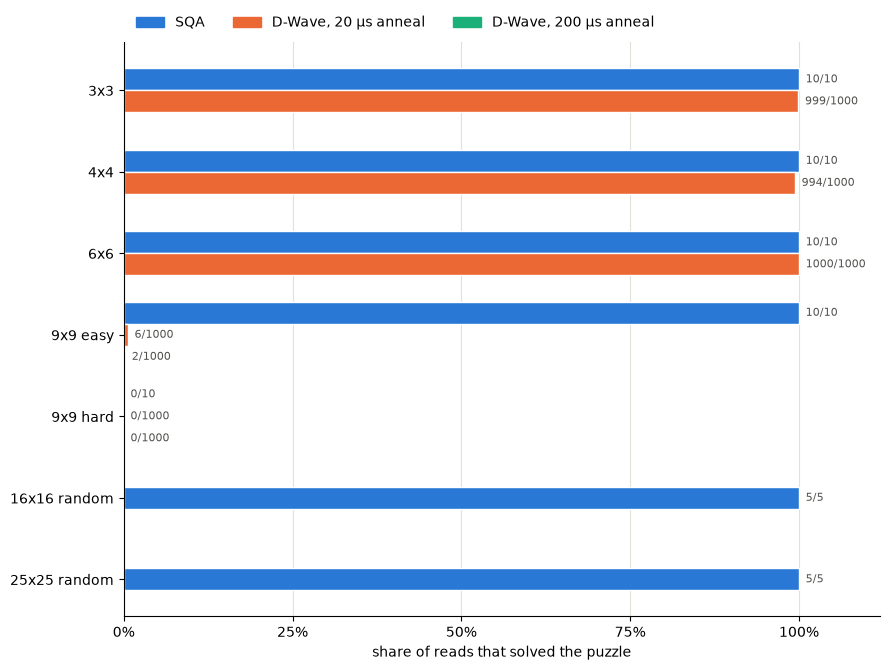

In [7]:
methods = {"SQA": "#2a78d6", "D-Wave, 20 µs anneal": "#eb6834", "D-Wave, 200 µs anneal": "#1baf7a"}
names = list(puzzles)
height = 0.27

figure, ax = plt.subplots(figsize=(9, 0.8 * len(names) + 1.2))
for y, name in enumerate(names):
    ran = [method for method in methods if (name, method) in results]
    for j, method in enumerate(ran):
        solved, total = results[name, method]
        offset = y + (j - (len(ran) - 1) / 2) * height  # centred on the puzzle's label
        ax.barh(offset, solved / total, height, color=methods[method], edgecolor="white", linewidth=1)
        ax.text(solved / total + 0.01, offset, f"{solved}/{total}", va="center", fontsize=8, color="#52514e")

ax.set_yticks(range(len(names)), [name.replace("_", " ") for name in names])
ax.invert_yaxis()
ax.set_xlim(0, 1.12)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("share of reads that solved the puzzle")
handles = [Patch(color=colour, label=method) for method, colour in methods.items()]
ax.legend(handles=handles, ncols=3, loc="lower left", bbox_to_anchor=(0, 1), frameon=False)
ax.grid(axis="x", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
figure.tight_layout()
plt.savefig("figures/solved.png", dpi=150)

### What this shows

- The encoding works. The ideal annealer finds a solution of the 3x3 with probability 0.734, and SQA solves every puzzle but one on every read, including the random 16x16 and 25x25 with 445 and 789 qubits.
- Difficulty depends more on a puzzle's structure than on its size. The hard 9x9 has 21 clues and a unique solution, and the best of its SQA reads still has energy 4.
- D-Wave solves the 3x3, 4x4 and 6x6 on at least 994 of 1,000 reads. The easy 9x9 is where it runs out: its 153 qubits need 500 to 600 on the chip, in chains of up to 9, and only 6 and 2 of its reads solved it. An earlier run of this cell solved 3 and 325, with a different embedding each time, so at this size the results vary a lot from run to run.
- None of the 2,000 reads of the hard 9x9 solved it; its 254 qubits need about 2,000 on the chip, in chains of up to 19.
- The SQA times are for a laptop, and say nothing about a quantum speed-up.